In [1]:
import matplotlib.pyplot as plt
import pandas as pd


In [2]:
dfs = pd.read_csv("sample_placement_training_data_100.csv")
dfs.rename(columns={"cgppa":"cgpa"},inplace=True)
dfs.to_csv("sample_placement_training_data_100.csv",index=False)
dfs

,iq,cgpa,placement
0,125,5.56,No
1,100,6.12,No
2,128,8.70,Yes
3,122,7.11,No
4,98,6.16,No
...,...,...,...
95,101,6.98,No
96,104,7.29,Yes
97,89,5.05,No
98,121,9.98,Yes


In [3]:
dfs.head()

,iq,cgpa,placement
0,125,5.56,No
1,100,6.12,No
2,128,8.70,Yes
3,122,7.11,No
4,98,6.16,No


In [4]:
dfs.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   iq         100 non-null    int64  
 1   cgpa       100 non-null    float64
 2   placement  100 non-null    str    
dtypes: float64(1), int64(1), str(1)
memory usage: 2.5 KB


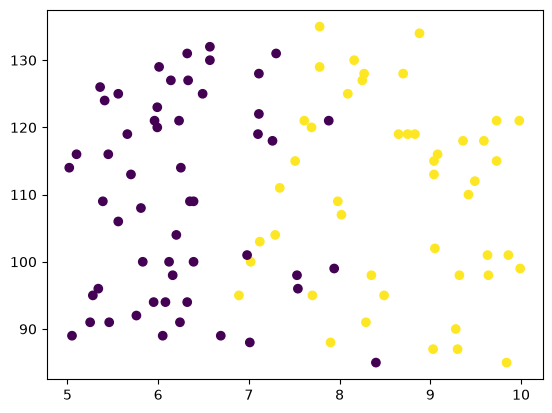

In [5]:
plt.scatter(dfs['cgpa'],dfs['iq'],c=dfs['placement'].map({"Yes":1,"No":0}))

In [6]:
X = dfs.iloc[:,[0,1]]
Y = dfs.iloc[:,[-1]]
from sklearn.model_selection import train_test_split

In [7]:
x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size=0.1)

In [8]:
x_train

,iq,cgpa
7,102,9.05
71,88,7.01
4,98,6.16
26,87,9.03
77,85,9.84
...,...,...
31,120,7.69
1,100,6.12
68,91,8.29
44,96,7.54


In [9]:
y_train

,placement
7,Yes
71,No
4,No
26,Yes
77,Yes
...,...
31,Yes
1,No
68,Yes
44,No


In [10]:
x_test

,iq,cgpa
95,101,6.98
33,99,9.99
56,98,9.64
81,101,9.63
93,121,7.61
12,131,7.30
22,119,8.65
58,127,8.25
15,121,5.96
41,106,5.56


In [11]:
y_test

,placement
95,No
33,Yes
56,Yes
81,Yes
93,Yes
12,No
22,Yes
58,Yes
15,No
41,No


In [12]:
from sklearn.linear_model import LogisticRegression


In [13]:
clf = LogisticRegression()

In [14]:
clf.fit(x_train,y_train)

d:\100-Days-Of-ML\.venv\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [15]:
y_pred = clf.predict(x_test)

In [16]:
y_test

,placement
95,No
33,Yes
56,Yes
81,Yes
93,Yes
12,No
22,Yes
58,Yes
15,No
41,No


In [17]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test,y_pred)

1.0

In [18]:
import pickle

pickle.dump(clf,open('model.pkl','wb'))


Ordinal Encoding

In [19]:
dfl = pd.read_csv("customer.csv")

dfl = dfl.iloc[:,2:]


In [20]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test= train_test_split(dfl.iloc[:,0:2],dfl.iloc[:,-1])

In [21]:
x_train.head()

,review,education
35,Poor,School
30,Average,UG
47,Good,PG
19,Poor,PG
45,Poor,PG


In [22]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder()

en = OrdinalEncoder(categories=[['Poor',"Average","Good"],["School","UG","PG"]])
en.fit(x_train)

x_train = en.transform(x_train)

x_test = en.transform(x_test)



In [23]:
from sklearn.preprocessing import LabelEncoder

labeler  = LabelEncoder()

labeler.fit(y_train)

y_train = labeler.transform(y_train)
y_test = labeler.transform(y_test)

y_train

array([1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1,
       1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1])

One-Hot-Encoding

In [24]:
data = pd.read_csv("cars.csv")


In [25]:
import numpy as np
import pandas as pd

pd.get_dummies(data,columns=['fuel','owner'],dtype=int,drop_first=True)


,brand,km_driven,selling_price,fuel_Diesel,fuel_LPG,fuel_Petrol,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,Maruti,145500,450000,1,0,0,0,0,0,0
1,Skoda,120000,370000,1,0,0,0,1,0,0
2,Honda,140000,158000,0,0,1,0,0,0,1
3,Hyundai,127000,225000,1,0,0,0,0,0,0
4,Maruti,120000,130000,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
8123,Hyundai,110000,320000,0,0,1,0,0,0,0
8124,Hyundai,119000,135000,1,0,0,1,0,0,0
8125,Maruti,120000,382000,1,0,0,0,0,0,0
8126,Tata,25000,290000,1,0,0,0,0,0,0


In [26]:
data

,brand,km_driven,fuel,owner,selling_price
0,Maruti,145500,Diesel,First Owner,450000
1,Skoda,120000,Diesel,Second Owner,370000
2,Honda,140000,Petrol,Third Owner,158000
3,Hyundai,127000,Diesel,First Owner,225000
4,Maruti,120000,Petrol,First Owner,130000
...,...,...,...,...,...
8123,Hyundai,110000,Petrol,First Owner,320000
8124,Hyundai,119000,Diesel,Fourth & Above Owner,135000
8125,Maruti,120000,Diesel,First Owner,382000
8126,Tata,25000,Diesel,First Owner,290000


In [27]:
from sklearn.model_selection import train_test_split

x= data.iloc[:,0:4]
y = data.iloc[:,-1]
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2)
x

,brand,km_driven,fuel,owner
0,Maruti,145500,Diesel,First Owner
1,Skoda,120000,Diesel,Second Owner
2,Honda,140000,Petrol,Third Owner
3,Hyundai,127000,Diesel,First Owner
4,Maruti,120000,Petrol,First Owner
...,...,...,...,...
8123,Hyundai,110000,Petrol,First Owner
8124,Hyundai,119000,Diesel,Fourth & Above Owner
8125,Maruti,120000,Diesel,First Owner
8126,Tata,25000,Diesel,First Owner


In [28]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder()
new_x_train = ohe.fit_transform(x_train[["fuel","owner"]]).toarray()
new_x_test= ohe.fit_transform(x_test[["fuel","owner"]]).toarray()


x_train[['brand',"km_driven"]].head()


,brand,km_driven
4012,Mahindra,22000
1139,Toyota,68089
1659,Mahindra,176000
2969,Ford,60000
7232,Tata,104000


In [29]:
x_train.values

array([['Mahindra', 22000, 'Petrol', 'First Owner'],
       ['Toyota', 68089, 'Petrol', 'First Owner'],
       ['Mahindra', 176000, 'Diesel', 'Second Owner'],
       ...,
       ['Tata', 180000, 'Diesel', 'First Owner'],
       ['Ford', 80000, 'Diesel', 'First Owner'],
       ['Hyundai', 44000, 'Petrol', 'Second Owner']],
      shape=(6502, 4), dtype=object)

In [30]:
np.hstack((x_train[['brand','km_driven']].values,new_x_train))

array([['Mahindra', 22000, 0.0, ..., 0.0, 0.0, 0.0],
       ['Toyota', 68089, 0.0, ..., 0.0, 0.0, 0.0],
       ['Mahindra', 176000, 0.0, ..., 1.0, 0.0, 0.0],
       ...,
       ['Tata', 180000, 0.0, ..., 0.0, 0.0, 0.0],
       ['Ford', 80000, 0.0, ..., 0.0, 0.0, 0.0],
       ['Hyundai', 44000, 0.0, ..., 1.0, 0.0, 0.0]],
      shape=(6502, 11), dtype=object)

In [31]:
threshold = 100
counts = x_train['brand'].value_counts()
repl = counts[counts<=threshold].index
pd.get_dummies(x_train['brand'].replace(repl,"uncommon"),dtype=int)

,Chevrolet,Ford,Honda,Hyundai,Mahindra,Maruti,Renault,Tata,Toyota,Volkswagen,uncommon
4012,0,0,0,0,1,0,0,0,0,0,0
1139,0,0,0,0,0,0,0,0,1,0,0
1659,0,0,0,0,1,0,0,0,0,0,0
2969,0,1,0,0,0,0,0,0,0,0,0
7232,0,0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
5437,1,0,0,0,0,0,0,0,0,0,0
5747,1,0,0,0,0,0,0,0,0,0,0
2903,0,0,0,0,0,0,0,1,0,0,0
4274,0,1,0,0,0,0,0,0,0,0,0


In [32]:
import numpy as np

df = pd.read_csv('covid_toy.csv')
df.head(2)

,age,gender,fever,cough,city,has_covid
0,60,Male,103.0,Mild,Kolkata,No
1,27,Male,100.0,Mild,Delhi,Yes


In [33]:
from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test = train_test_split(df.iloc[:,0:5],df.iloc[:,-1])
x_train = x_train.dropna()
x_train.iloc[:,3:4].head(2)

,cough
44,Strong
92,Strong


In [34]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

oe = OrdinalEncoder(categories=[['Mild','Strong']])
oe.fit(x_train.iloc[:,3:4])

new_x_train_ordinal = oe.transform(x_train.iloc[:,3:4])


In [35]:
ohe = OneHotEncoder()
ohe.fit(x_train[['gender','city']])
new_x_train_nominal = ohe.transform(x_train.iloc[:,[1,4]]).toarray()

np.hstack((new_x_train_ordinal,new_x_train_nominal,x_train[['age','fever']])).shape


(68, 9)

Column transfromer

In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

df = pd.read_csv("covid_toy.csv")


x_train,x_test,y_train,y_test = train_test_split(df.iloc[:,0:5],df.iloc[:,-1],test_size=0.2,random_state=42)
x_train['fever'] = x_train['fever'].fillna(x_train['fever'].mean())
x_train

,age,gender,fever,cough,city
55,81,Female,101.0,Mild,Mumbai
88,5,Female,100.0,Mild,Kolkata
26,19,Female,100.0,Mild,Kolkata
42,27,Male,100.0,Mild,Delhi
69,73,Female,103.0,Mild,Delhi
...,...,...,...,...,...
60,24,Female,102.0,Strong,Bangalore
71,75,Female,104.0,Strong,Delhi
14,51,Male,104.0,Mild,Bangalore
92,82,Female,102.0,Strong,Kolkata


In [37]:
transformer = ColumnTransformer(
    transformers=[
    ('tf1',OrdinalEncoder(categories=[['Mild',"Strong"]]),['cough']),
    ('tf2',OneHotEncoder(sparse_output=False,drop='first'),['gender','city']),
    ('tf3',SimpleImputer(strategy='mean'),['fever'])                                            
],
remainder='passthrough'
)

transformer.fit_transform(x_train)

array([[  0.,   0.,   0.,   0.,   1., 101.,  81.],
       [  0.,   0.,   0.,   1.,   0., 100.,   5.],
       [  0.,   0.,   0.,   1.,   0., 100.,  19.],
       [  0.,   1.,   1.,   0.,   0., 100.,  27.],
       [  0.,   0.,   1.,   0.,   0., 103.,  73.],
       [  1.,   1.,   0.,   1.,   0., 103.,  70.],
       [  0.,   0.,   1.,   0.,   0., 102.,  49.],
       [  1.,   0.,   0.,   1.,   0., 101.,  51.],
       [  0.,   0.,   1.,   0.,   0., 101.,  64.],
       [  0.,   0.,   0.,   1.,   0., 101.,  83.],
       [  0.,   0.,   0.,   0.,   1.,  98.,  65.],
       [  0.,   0.,   0.,   0.,   0., 104.,  18.],
       [  0.,   0.,   0.,   0.,   0., 103.,  16.],
       [  0.,   1.,   0.,   1.,   0., 104.,  16.],
       [  0.,   1.,   0.,   1.,   0., 100.,  27.],
       [  0.,   0.,   0.,   0.,   0., 101.,  84.],
       [  0.,   1.,   0.,   1.,   0., 104.,  51.],
       [  0.,   0.,   0.,   0.,   0., 102.,  69.],
       [  1.,   0.,   0.,   0.,   0., 102.,  82.],
       [  0.,   0.,   0.,   1.,

In [38]:
df = pd.read_csv("train.csv")
df.drop(columns=['PassengerId','Name','Ticket','Cabin'],inplace=True)


In [84]:
x_train,x_test,y_train,y_test = train_test_split(df.iloc[:,1:],df.iloc[:,0],test_size=0.2)
x_train.isnull().sum()

Pclass        0
Sex           0
Age         139
SibSp         0
Parch         0
Fare          0
Embarked      1
dtype: int64

In [85]:
# Simple Imputation

si_age= SimpleImputer()
si_embarked= SimpleImputer(strategy='most_frequent')

x_train_age = si_age.fit_transform(x_train[['Age']])
x_train_embarked = si_embarked.fit_transform(x_train[['Embarked']])

x_test_age = si_age.transform(x_test[['Age']])
x_test_embarked = si_embarked.transform(x_test[['Embarked']])

In [86]:
x_train.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
144,2,male,18.0,0,0,11.5000,S
224,1,male,38.0,1,0,90.0000,S
697,3,female,NaN,0,0,7.7333,Q
127,3,male,24.0,0,0,7.1417,S
544,1,male,50.0,1,0,106.4250,C


In [87]:
from sklearn.preprocessing import OneHotEncoder

ohe_sex = OneHotEncoder(sparse_output=False,handle_unknown='ignore')
ohe_Embarked = OneHotEncoder(sparse_output=False,handle_unknown='ignore')

x_train_sex = ohe_sex.fit_transform(x_train[['Sex']])
x_train_embarked= ohe_sex.fit_transform(x_train[['Embarked']])


x_test_sex = ohe_sex.fit_transform(x_test[['Sex']])
x_test_embarked= ohe_sex.fit_transform(x_test[['Embarked']])

x_remaining_train = x_train.drop(columns=['Sex','Embarked','Age'])
x_rem_test = x_test.drop(columns=['Sex','Embarked','Age'])




In [92]:
x_train_encoded = np.concatenate((x_train_age,x_train_sex,x_train_embarked,x_remaining_train),axis=1)
x_test_encoded=np.concatenate((x_test_age,x_test_sex,x_test_embarked,x_rem_test),axis=1)


In [94]:
from sklearn.tree import DecisionTreeClassifier

clf = DecisionTreeClassifier()

clf.fit(x_train_encoded,y_train)

y_pred = clf.predict(x_test_encoded)

from sklearn.metrics import accuracy_score

accuracy_score(y_test,y_pred)

0.8044692737430168